# compact 特征研究

单码生成 `calc_compact_features` 的 compact 列（37 derivable + ATR + peak + rank），
只做 matplotlib 展示。

入口是**静态方法**，范式同老树 cookbook 的 `calc_stock_poolcoef_analysis(..., ret_meta=True)`：

```python
features = CompactPipeline.calc_features('600519')
ohlc, features, display_name = CompactPipeline.calc_features('600519', offset='2026-10-20', ret_meta=True)
```

⚠️ 只读：不落库、不写水位、不做实时合并。默认取最近交易日。


In [1]:
# 允许从 cookbooks/ 直接打开：向上找到含 GolemQ/__init__.py 的仓库根并加进 sys.path
import os, sys
_here = os.path.abspath(os.getcwd())
for _ in range(6):
    if os.path.isfile(os.path.join(_here, 'GolemQ', '__init__.py')):
        if _here not in sys.path:
            sys.path.insert(0, _here)
        break
    _parent = os.path.dirname(_here)
    if _parent == _here:
        break
    _here = _parent

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from GolemQ.core.constants import AKA, FEATURES as FTR, FIELD
from GolemQ.models.alias import PFL
from GolemQ.pipeline.compact import CompactPipeline

# 中文：与 4.4 老树 `utils/gfx.py` 同口径（Windows 自带微软雅黑）
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 80)
pd.set_option('expand_frame_repr', False)

In [2]:
# 研究参数
code = '000711'
offset = ''          # '' = 最近交易日；或 'YYYY-MM-DD'

# 老树 `FLD.DEA_NORM_WEEKLY` 的落库名（新 review 契约没有这列，cell 5 现算）
DEA_NORM_WEEKLY = 'DEA_NORM_WEK'

In [3]:
import time

_t0 = time.perf_counter()
ohlc, features, display_name = CompactPipeline.calc_features(
    code, offset=offset, verbose=False, ret_meta=True)

print(f'{code} {display_name}  {len(features)} bars  {len(features.columns)} cols')
print(f'[timing] calc_compact_features: {time.perf_counter() - _t0:.2f}s')
features.tail(3)[[
    AKA.CLOSE, FIELD.CCI_NORM, FIELD.RSI, FIELD.MAPOWER30_MAJOR,
    FIELD.STOCK_SCORE_M15_NORM, FIELD.ATR_Stopline, PFL.STOCK_PORTFOLIO_RANK,
]]


000711 京蓝科技  2059 bars  95 cols
[timing] calc_compact_features: 2.23s


Y:\Projects\GolemQ\GolemQ\analysis\xgboost\rank.py:339: RuntimeWarning: invalid value encountered in cast
  features[FIELD.MACD_CROSS_SX_BEFORE_MAJOR].values.astype(np.int16))


,,close,CCI_NORM,RSI,mpwr3Maj,ssm15Norm,ATR_Stopline,rStkPflRnk
ts,code,,,,,,,
2026-10-26 11:30:00,000711,3.59,NaN,NaN,NaN,NaN,-1.0,NaN
2026-10-26 14:00:00,000711,3.57,NaN,NaN,NaN,NaN,-1.0,NaN
2026-10-26 15:00:00,000711,3.55,0.322523,19.795784,0.0,0.203333,-1.0,NaN


## 附加 reality 特征（只读）

把 review/coldstart 与 ChartScan 的列接到 `features` 上（实现已收口到 `GolemQ/analysis/reality_attach.py`）：

- `bstStgBf`（`FLD.BOOTSTRAP_STAGE_BEFORE` 的落库名）← `stock_reality_feat_60min`；
- `_REAL` 系列（`zDLagMajR` / `poly9MajR` / `m9tMajR` / `rTrePrcMajR` …）← `stock_reality_feat_day`；
- ChartScan 三条时间线：`ClsMaj`（day）/ `Class`（60min）/ `ClsMin`（15min）。

⚠️ day 列按**因果**映射（盘中用上一交易日、15:00 用当日）；15min 只取**当前 60min bar 之前最后一个已完成**的 15min 值。

**K 线副坐标轴的两条周线归一曲线**：

- `POLYNOMIAL9_NORM_WEEKLY_REAL`（`poly9NorWekR`）—— 已由 review 落在 day 表；
- `DEA_NORM_WEK`（老树 `FLD.DEA_NORM_WEEKLY`）—— 新 review 契约**没有**这列，
  由日线 → 周线现算（周线 DEA → mapower 归一 0..1，按「上一已完成周」映射）。

- 若 review 尚未写当日行，相关列保持 NaN；需在 review 侧补齐（不在 notebook 重算，D68）。


In [ ]:
# 附加 reality / coldstart / ChartScan 时间线（实现在 analysis/reality_attach.py）
import time
from GolemQ.analysis.reality_attach import DEA_NORM_WEEKLY, attach_reality_feats

_t0 = time.perf_counter()
_ts_all = pd.DatetimeIndex(pd.to_datetime(features.index.get_level_values(0)))
_, _day_ohlc, _ = CompactPipeline._fetch_frames(code, pd.Timestamp(_ts_all.max()))
features, loaded = attach_reality_feats(
    features, code,
    market_type=CompactPipeline.market_type_of(code),
    day_ohlc=_day_ohlc,
    verbose=False,
)
print('[attach] {}  ({}s)'.format(
    {k: len(v) for k, v in loaded.items()}, time.perf_counter() - _t0))
_show_cols = list(dict.fromkeys(c for cols in loaded.values() for c in cols))
features[_show_cols].tail(3)


In [ ]:
# 价格 K 线（mplfinance 蜡烛）+ ATR 通道 + 线性回归 + MA90
# 副坐标轴：周线归一曲线 POLYNOMIAL9_NORM_WEEKLY_REAL / DEA_NORM_WEEKLY（0..1）
import mplfinance as mpf
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

window = 1920
f = features.tail(window)
dates = pd.to_datetime(f.index.get_level_values(0))
x = np.arange(len(f))


def _time_axis(ax, dates, n=8):
    step = max(1, len(dates) // n)
    idx = np.arange(0, len(dates), step)
    ax.set_xticks(idx)
    ax.set_xticklabels([pd.Timestamp(d).strftime('%m-%d %H:%M')
                        for d in dates[idx]], fontsize=8)


# mplfinance 要 DatetimeIndex + 首字母大写的 OHLC 列
ohlc = f[[AKA.OPEN, AKA.HIGH, AKA.LOW, AKA.CLOSE]].copy()
ohlc.columns = ['Open', 'High', 'Low', 'Close']
ohlc.index = pd.DatetimeIndex(dates)

# ⚠️ mplfinance 会用 style 的 rc 覆盖全局 rcParams —— 中文字体必须
# 同时塞进 style，否则标题/刻度会退回 DejaVu Sans（豆腐块）。
ZH_RC = {
    'font.family': 'sans-serif',
    'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'DejaVu Sans'],
    'axes.unicode_minus': False,
}
plt.rcParams.update(ZH_RC)

mc = mpf.make_marketcolors(up='#d62728', down='#2ca02c',
                           edge='inherit', wick='inherit')
style = mpf.make_mpf_style(marketcolors=mc, gridstyle='--',
                           gridcolor='#dddddd', rc=ZH_RC)

addplots = [
    mpf.make_addplot(f[FIELD.LINEAREG_PRICE].to_numpy(),
                     color='orange', linestyle='-.', width=1),
    mpf.make_addplot(f[AKA.CLOSE].rolling(90).mean().to_numpy(),
                     color='magenta', linestyle='--', width=1),
    mpf.make_addplot(f[FIELD.ATR_Stopline_PRICE].to_numpy(),
                     color='green', width=1),
]

# 副坐标轴上的两条周线归一曲线（缺列 / 全 NaN 时自动跳过）
WEEKLY_CURVES = [
    (FTR.POLYNOMIAL9_NORM_WEEKLY_REAL, 'tab:cyan',
     'POLYNOMIAL9_NORM_WEEKLY_REAL'),
    (DEA_NORM_WEEKLY, 'tab:brown', 'DEA_NORM_WEEKLY'),
]
for col, color, label in WEEKLY_CURVES:
    if col in f.columns and f[col].notna().any():
        addplots.append(mpf.make_addplot(
            f[col].to_numpy(), color=color, width=1.2,
            secondary_y=True, label=label))

fig, axes = mpf.plot(
    ohlc, type='candle', style=style, addplot=addplots,
    returnfig=True, figsize=(16, 7), warn_too_much_data=100000,
    xrotation=0, ylabel='price',
    title=f'{code} {display_name} — 60min OHLC / ATR band / LINEAREG',
)
ax = axes[0]
ax.fill_between(x, f[FIELD.ATR_LB].to_numpy(), f[FIELD.ATR_UB].to_numpy(),
                color='steelblue', alpha=0.12, zorder=0)

handles = [
    Line2D([0], [0], color='orange', ls='-.', label='LINEAREG_PRICE'),
    Line2D([0], [0], color='magenta', ls='--', label='MA90'),
    Line2D([0], [0], color='green', label='ATR_Stopline_PRICE'),
    Patch(facecolor='steelblue', alpha=0.2, label='ATR band'),
]
# 把副坐标轴的两条曲线并进同一个图例；只有真的加了副轴曲线才动 axes[-1]
if len(axes) > 1:
    sec = axes[-1]
    _sec_h, _sec_l = sec.get_legend_handles_labels()
    if _sec_h:
        sec.set_ylabel('weekly norm (0–1)', fontsize=9)
        sec.set_ylim(-0.05, 1.05)
        sec.tick_params(axis='y', labelsize=8)
        if sec.get_legend() is not None:
            sec.get_legend().remove()
        handles += _sec_h
ax.legend(handles=handles, loc='upper left', fontsize=9)
_time_axis(ax, dates)
# mplfinance 自己管布局；tight_layout 会告警，别加
plt.show()

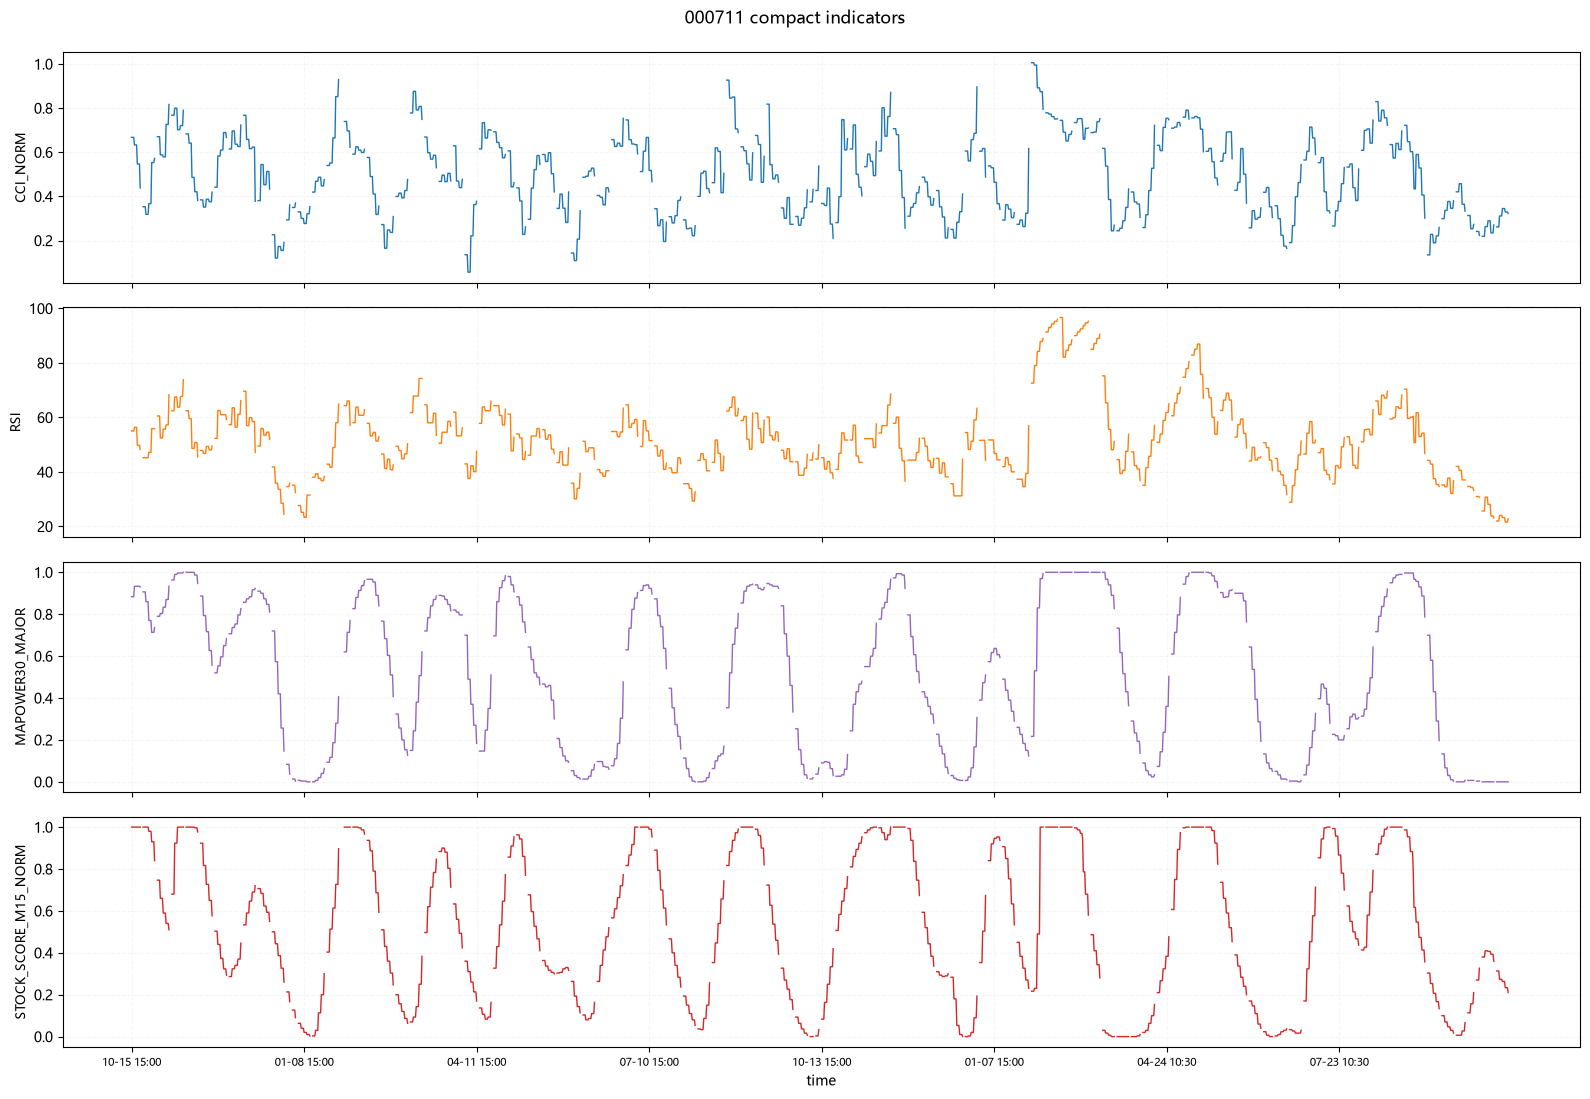

In [6]:
# 指标面板：CCI / RSI / MAPOWER30 / 股票评分
panels = [
    (FIELD.CCI_NORM, 'CCI_NORM', 'tab:blue'),
    (FIELD.RSI, 'RSI', 'tab:orange'),
    (FIELD.MAPOWER30_MAJOR, 'MAPOWER30_MAJOR', 'tab:purple'),
    (FIELD.STOCK_SCORE_M15_NORM, 'STOCK_SCORE_M15_NORM', 'tab:red'),
]
fig, axes = plt.subplots(len(panels), 1, figsize=(16, 11), sharex=True)
for ax, (col, label, color) in zip(axes, panels):
    ax.plot(x, f[col], color=color, lw=1)
    ax.set_ylabel(label, fontsize=9)
    ax.grid(alpha=0.25)
_time_axis(axes[-1], dates)
axes[-1].set_xlabel('time')
fig.suptitle(f'{code} compact indicators', y=0.995)
plt.tight_layout()
plt.show()


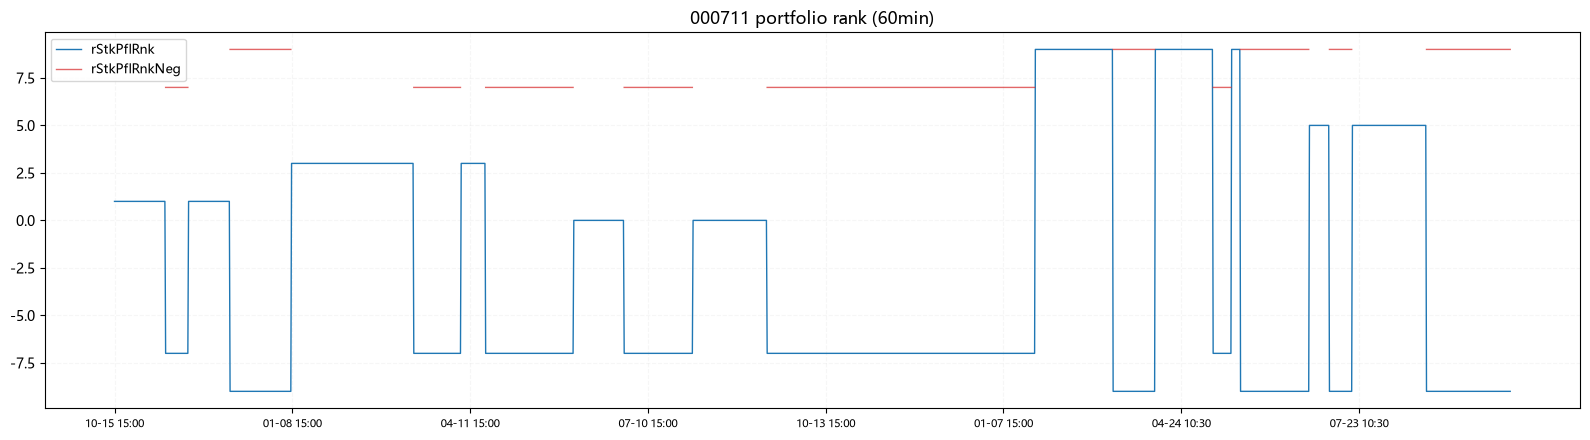

In [7]:
# rank / 收益
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(x, f[PFL.STOCK_PORTFOLIO_RANK], color='tab:blue', lw=1,
        label=PFL.STOCK_PORTFOLIO_RANK)
ax.plot(x, f[PFL.STOCK_PORTFOLIO_RANK_NEGATIVE], color='tab:red', lw=1,
        alpha=0.7, label=PFL.STOCK_PORTFOLIO_RANK_NEGATIVE)
ax.set_title(f'{code} portfolio rank (60min)')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.25)
_time_axis(ax, dates)
plt.tight_layout()
plt.show()
